In [4]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pathlib import Path

# Thêm đường dẫn gốc của project vào sys.path để gọi được module từ thư mục src/
current_dir = Path(os.getcwd())
while current_dir.name != '' and not (current_dir / 'data').exists():
    current_dir = current_dir.parent
data_path = current_dir / 'data' / 'raw' / 'AirPassengers.csv'

print("Đang tìm file tại:", data_path)
if not data_path.exists():
    print("CẢNH BÁO: Vẫn không thấy file! Hãy kiểm tra lại xem file có bị đặt tên là .csv.csv không.")
else:
    print("Đã tìm thấy file! Đang tiến hành đọc dữ liệu...\n")

# Cấu hình hiển thị đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

Đang tìm file tại: d:\vscode\Lab_TimeSeries\data\raw\AirPassengers.csv
Đã tìm thấy file! Đang tiến hành đọc dữ liệu...



1. Năm quan sát đầu tiên:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



2. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB

3. Thống kê mô tả:


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000



4. Kiểm tra dữ liệu thiếu:
Passengers    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 144
Số giá trị thiếu: 0


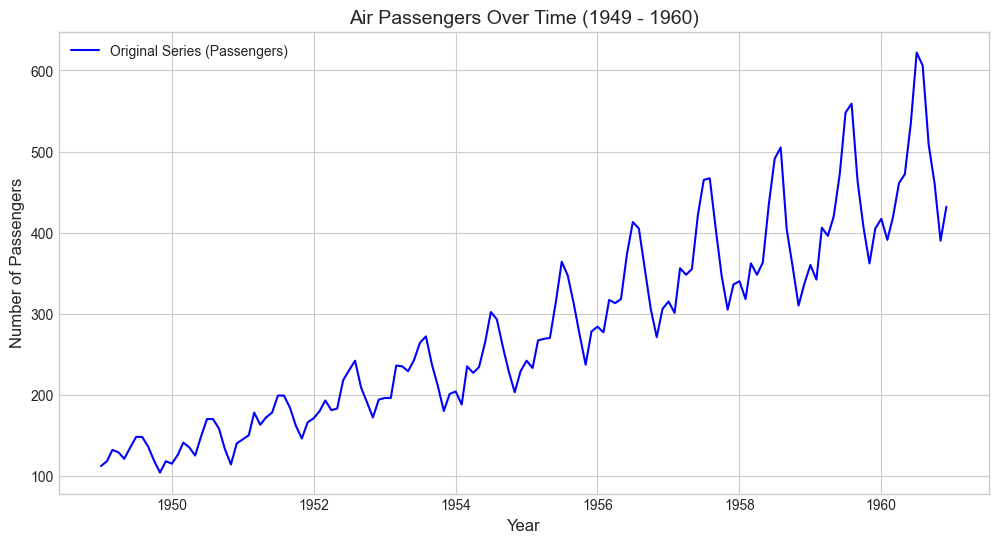

In [6]:
# Đọc dữ liệu
from src.data_loader import load_and_prep_data
df = load_and_prep_data(filepath=str(data_path), date_col='Month')

print("1. Năm quan sát đầu tiên:")
display(df.head())

print("\n2. Thông tin dữ liệu:")
df.info()

print("\n3. Thống kê mô tả:")
display(df["Passengers"].describe().to_frame())

print("\n4. Kiểm tra dữ liệu thiếu:")
print(df.isna().sum())

print("\n5. Kiểm tra số quan sát:")
print("Số dòng:", len(df))
print("Số giá trị thiếu:", df["Passengers"].isna().sum())

# Vẽ đồ thị chuỗi gốc
plt.plot(df.index, df['Passengers'], color='blue', label='Original Series (Passengers)')
plt.title('Air Passengers Over Time (1949 - 1960)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Passengers', fontsize=12)
plt.legend()
plt.show()

### Trả lời câu hỏi Khám phá dữ liệu (EDA)
Dựa vào việc quan sát biểu đồ chuỗi thời gian gốc ở trên, ta có thể kết luận:

1. **Dữ liệu có xu hướng (Trend) không?**
   **Trả lời: CÓ.** Đường đồ thị có xu hướng đi lên rõ rệt từ năm 1949 đến năm 1960. Số lượng hành khách trung bình tăng dần qua các năm.

2. **Dữ liệu có mùa vụ (Seasonality) không?**
   **Trả lời: CÓ.** Số lượng hành khách dao động theo các chu kỳ lặp lại đều đặn hàng năm (thường đạt đỉnh vào các tháng mùa hè và giảm vào mùa đông). Càng về sau, biên độ dao động của chu kỳ này càng lớn dần.

3. **Chuỗi dữ liệu có dừng (Stationary) không?**
   **Trả lời: KHÔNG.** Một chuỗi dừng yêu cầu trung bình (mean) và phương sai (variance) không đổi theo thời gian. Ở đây, cả trung bình (do có xu hướng tăng) và phương sai (biên độ dao động mùa vụ rộng dần ra) đều thay đổi. Do đó, ta bắt buộc phải dùng sai phân ở Giai đoạn 3 để khắc phục tính "không dừng" này.

# Chia tập train-test 80-20

Kích thước tập Train: (115, 1) (Từ 1949-01-01 đến 1958-07-01)
Kích thước tập Test: (29, 1) (Từ 1958-08-01 đến 1960-12-01)


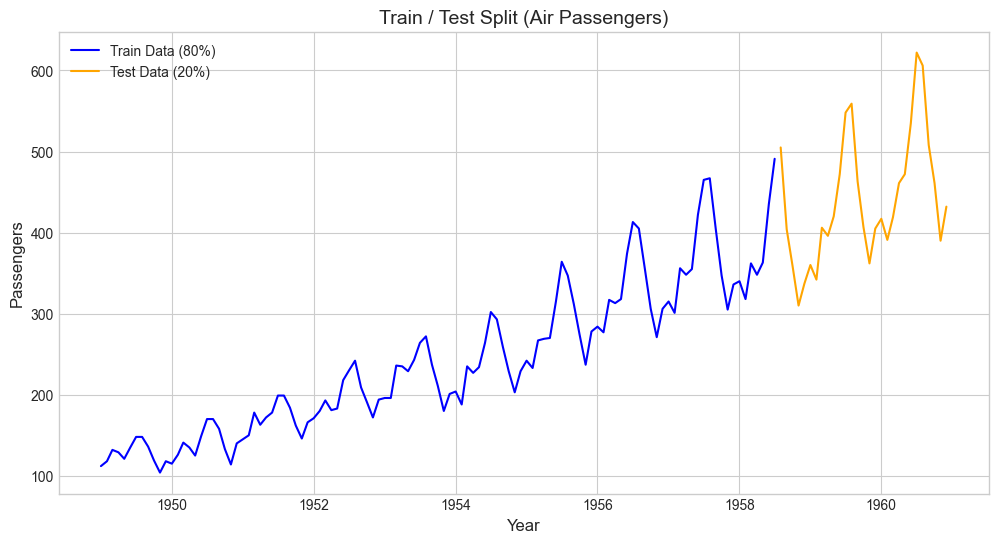

Đã lưu file train_data.csv và test_data.csv thành công vào:
d:\vscode\Lab_TimeSeries\data\processed\lab02


In [7]:
# Tự động định vị lại thư mục gốc dự án (để lưu file an toàn tuyệt đối)
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
    
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)

print(f"Kích thước tập Train: {train_df.shape} (Từ {train_df.index.min().date()} đến {train_df.index.max().date()})")
print(f"Kích thước tập Test: {test_df.shape} (Từ {test_df.index.min().date()} đến {test_df.index.max().date()})")

plt.figure(figsize=(12, 6))
plt.plot(train_df.index, train_df['Passengers'], label='Train Data (80%)', color='blue')
plt.plot(test_df.index, test_df['Passengers'], label='Test Data (20%)', color='orange')
plt.title('Train / Test Split (Air Passengers)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Passengers', fontsize=12)
plt.legend()
plt.show()

# Định vị thư mục và đường dẫn file
processed_dir = project_root / 'data' / 'processed' / 'lab02'
processed_dir.mkdir(parents=True, exist_ok=True)

train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

# Kiểm tra tồn tại trước khi lưu
if not train_file.exists() or not test_file.exists():
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    print(f"Đã lưu file train_data.csv và test_data.csv thành công vào:\n{processed_dir}")
else:
    print(f"Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!")
